In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")

In [27]:
data_path = "../outputs/cleaned_data"

patients = pd.read_csv(f"{data_path}/patients_cleaned.csv")
opd = pd.read_csv(f"{data_path}/opd_cleaned.csv")
admissions = pd.read_csv(f"{data_path}/admissions_cleaned.csv")
lab = pd.read_csv(f"{data_path}/lab_cleaned.csv")
billing = pd.read_csv(f"{data_path}/billing_cleaned.csv")

print("All datasets loaded successfully!")

print("Patients:", patients.shape)
print("OPD:", opd.shape)
print("Admissions:", admissions.shape)
print("Lab Tests:", lab.shape)
print("Billing:", billing.shape)

All datasets loaded successfully!
Patients: (50000, 6)
OPD: (180000, 8)
Admissions: (40000, 9)
Lab Tests: (120000, 8)
Billing: (160000, 11)


In [28]:
opd["visit_date"] = pd.to_datetime(opd["visit_date"])
admissions["admission_date"] = pd.to_datetime(admissions["admission_date"])
lab["test_date"] = pd.to_datetime(lab["test_date"])
billing["bill_date"] = pd.to_datetime(billing["bill_date"])

print("Date columns converted successfully!")

Date columns converted successfully!


In [29]:
reference_date = pd.Timestamp("2025-12-31")

print("Reference Date:", reference_date)

Reference Date: 2025-12-31 00:00:00


In [30]:
last_visit = opd.groupby("patient_id")["visit_date"].max()

recency = (reference_date - last_visit).dt.days

print("Recency calculated successfully!")
print(recency.head())

Recency calculated successfully!
patient_id
P000001    249
P000002    433
P000003    117
P000004     36
P000005    150
Name: visit_date, dtype: int64


In [31]:
frequency = opd.groupby("patient_id").size()

print("Frequency calculated successfully!")
print(frequency.head())

Frequency calculated successfully!
patient_id
P000001    3
P000002    1
P000003    6
P000004    4
P000005    1
dtype: int64


In [32]:
billing["corrected_amount"] = (
    billing["base_amount"] * (1 + billing["gst_rate"])
).round(2)

monetary = billing.groupby("patient_id")["corrected_amount"].sum()

print("Monetary value calculated successfully!")
print(monetary.head())

Monetary value calculated successfully!
patient_id
P000001     4957.45
P000002     2429.05
P000003    26877.75
P000004    11662.68
P000005     9362.15
Name: corrected_amount, dtype: float64


In [33]:
admission_frequency = admissions.groupby("patient_id").size()

print("Admission frequency calculated successfully!")
print(admission_frequency.head())

Admission frequency calculated successfully!
patient_id
P000003    5
P000006    2
P000010    1
P000012    4
P000014    3
dtype: int64


In [34]:
average_los = admissions.groupby("patient_id")[
    "length_of_stay_days"
].mean()

print("Average length of stay calculated successfully!")
print(average_los.head())

Average length of stay calculated successfully!
patient_id
P000003     4.000000
P000006    17.500000
P000010     4.000000
P000012     3.000000
P000014     3.333333
Name: length_of_stay_days, dtype: float64


In [35]:
lab_frequency = lab.groupby("patient_id").size()

print("Lab test frequency calculated successfully!")
print(lab_frequency.head())

Lab test frequency calculated successfully!
patient_id
P000001    1
P000002    1
P000003    6
P000004    5
P000005    1
dtype: int64


In [36]:
opd["year"] = opd["visit_date"].dt.year

yearly_visits = opd.pivot_table(
    index="patient_id",
    columns="year",
    values="visit_id",
    aggfunc="count",
    fill_value=0
)

for year in [2024, 2025]:
    if year not in yearly_visits.columns:
        yearly_visits[year] = 0

growth = (
    (yearly_visits[2025] - yearly_visits[2024])
    / yearly_visits[2024].replace(0, np.nan)
) * 100

# Identify patients with no 2024 baseline
no_growth_baseline = yearly_visits[2024] == 0

growth = growth.replace([np.inf, -np.inf], np.nan).fillna(0)

print("Visit growth calculated successfully!")
print(growth.head())

Visit growth calculated successfully!
patient_id
P000001    -50.0
P000002   -100.0
P000003    -50.0
P000004    200.0
P000005      0.0
dtype: float64


In [37]:
opd["month"] = opd["visit_date"].dt.month

monthly_activity = opd.pivot_table(
    index="patient_id",
    columns="month",
    values="visit_id",
    aggfunc="count",
    fill_value=0
)

seasonality = (
    monthly_activity.std(axis=1)
    / monthly_activity.mean(axis=1).replace(0, np.nan)
).fillna(0)

print("Seasonality calculated successfully!")
print(seasonality.head())

Seasonality calculated successfully!
patient_id
P000001    2.486326
P000002    3.464102
P000003    1.348400
P000004    1.954017
P000005    3.464102
dtype: float64


In [38]:
# Combine all patient-level features correctly

features = patients[
    ["patient_id", "home_hospital_id", "gender", "age"]
].copy()

# Map features using patient_id
features["Recency"] = features["patient_id"].map(recency)
features["Frequency"] = features["patient_id"].map(frequency)
features["Monetary"] = features["patient_id"].map(monetary)
features["Admission_Frequency"] = features["patient_id"].map(admission_frequency)
features["Average_LOS"] = features["patient_id"].map(average_los)
features["Lab_Frequency"] = features["patient_id"].map(lab_frequency)
features["Growth"] = features["patient_id"].map(growth)
features["Seasonality"] = features["patient_id"].map(seasonality)
features["No_Growth_Baseline"] = features["patient_id"].map(no_growth_baseline)

# Identify patients with OPD visits before filling missing values
features["Has_OPD_Visit"] = features["Frequency"].notna().astype(int)

# Fill missing values
features["Recency"] = features["Recency"].fillna(730)

features = features.fillna({
    "Frequency": 0,
    "Monetary": 0,
    "Admission_Frequency": 0,
    "Average_LOS": 0,
    "Lab_Frequency": 0,
    "Growth": 0,
    "Seasonality": 0,
    "No_Growth_Baseline": True
})

print("All patient features combined successfully!")
print("Feature dataset shape:", features.shape)

display(features.head())


All patient features combined successfully!
Feature dataset shape: (50000, 14)


C:\Users\AKSHITHA\AppData\Local\Temp\ipykernel_12528\2800588759.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  features = features.fillna({


,patient_id,home_hospital_id,gender,age,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Growth,Seasonality,No_Growth_Baseline,Has_OPD_Visit
0,P000001,H004,Male,60,249.0,3.0,4957.45,0.0,0.0,1.0,-50.0,2.486326,False,1
1,P000002,H002,Male,29,433.0,1.0,2429.05,0.0,0.0,1.0,-100.0,3.464102,False,1
2,P000003,H003,Male,28,117.0,6.0,26877.75,5.0,4.0,6.0,-50.0,1.348400,False,1
3,P000004,H001,Female,35,36.0,4.0,11662.68,0.0,0.0,5.0,200.0,1.954017,False,1
4,P000005,H002,Male,34,150.0,1.0,9362.15,0.0,0.0,1.0,0.0,3.464102,True,1


In [39]:
print("Feature Summary:")
display(features[
    [
        "Recency",
        "Frequency",
        "Monetary",
        "Admission_Frequency",
        "Average_LOS",
        "Lab_Frequency",
        "Seasonality"
    ]
].describe())

print("\nHas_OPD_Visit distribution:")
print(features["Has_OPD_Visit"].value_counts())

print("\nSample patient features:")
display(features.head(10))

Feature Summary:


,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,245.489160,3.600000,9085.588022,0.800000,2.598117,2.400000,1.903173
std,230.191692,3.010246,10419.316330,1.036736,3.408167,2.199931,1.002630
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,61.000000,1.000000,2102.517500,0.000000,0.000000,1.000000,1.287076
50%,160.000000,3.000000,5596.770000,0.000000,0.000000,2.000000,1.809068
75%,374.000000,5.000000,12230.842500,1.000000,4.666667,3.000000,2.335497
max,730.000000,21.000000,120465.700000,10.000000,30.000000,16.000000,3.464102



Has_OPD_Visit distribution:
Has_OPD_Visit
1    45287
0     4713
Name: count, dtype: int64

Sample patient features:


,patient_id,home_hospital_id,gender,age,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Growth,Seasonality,No_Growth_Baseline,Has_OPD_Visit
0,P000001,H004,Male,60,249.0,3.0,4957.45,0.0,0.0,1.0,-50.0,2.486326,False,1
1,P000002,H002,Male,29,433.0,1.0,2429.05,0.0,0.0,1.0,-100.0,3.464102,False,1
2,P000003,H003,Male,28,117.0,6.0,26877.75,5.0,4.0,6.0,-50.0,1.348400,False,1
3,P000004,H001,Female,35,36.0,4.0,11662.68,0.0,0.0,5.0,200.0,1.954017,False,1
4,P000005,H002,Male,34,150.0,1.0,9362.15,0.0,0.0,1.0,0.0,3.464102,True,1
5,P000006,H002,Male,52,361.0,2.0,31655.26,2.0,17.5,1.0,0.0,2.335497,False,1
6,P000007,H002,Male,70,43.0,2.0,2473.85,0.0,0.0,0.0,0.0,2.335497,False,1
7,P000008,H001,Male,45,77.0,3.0,6418.63,0.0,0.0,2.0,100.0,1.809068,False,1
8,P000009,H004,Female,19,15.0,1.0,1276.90,0.0,0.0,2.0,0.0,3.464102,True,1
9,P000010,H001,Male,36,42.0,1.0,2967.25,1.0,4.0,1.0,0.0,3.464102,True,1


In [40]:
print("Feature Dataset Information")
features.info()

print("\nMissing Values:")
print(features.isnull().sum())

print("\nStatistical Summary:")
display(features.describe())

Feature Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           50000 non-null  object 
 1   home_hospital_id     50000 non-null  object 
 2   gender               50000 non-null  object 
 3   age                  50000 non-null  int64  
 4   Recency              50000 non-null  float64
 5   Frequency            50000 non-null  float64
 6   Monetary             50000 non-null  float64
 7   Admission_Frequency  50000 non-null  float64
 8   Average_LOS          50000 non-null  float64
 9   Lab_Frequency        50000 non-null  float64
 10  Growth               50000 non-null  float64
 11  Seasonality          50000 non-null  float64
 12  No_Growth_Baseline   50000 non-null  bool   
 13  Has_OPD_Visit        50000 non-null  int64  
dtypes: bool(1), float64(8), int64(2), object(3)
memory usage: 

,age,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Growth,Seasonality,Has_OPD_Visit
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,51.993300,245.489160,3.600000,9085.588022,0.800000,2.598117,2.400000,1.197190,1.903173,0.905740
std,19.396178,230.191692,3.010246,10419.316330,1.036736,3.408167,2.199931,91.797289,1.002630,0.292193
min,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-100.000000,0.000000,0.000000
25%,35.000000,61.000000,1.000000,2102.517500,0.000000,0.000000,1.000000,-50.000000,1.287076,1.000000
50%,52.000000,160.000000,3.000000,5596.770000,0.000000,0.000000,2.000000,0.000000,1.809068,1.000000
75%,69.000000,374.000000,5.000000,12230.842500,1.000000,4.666667,3.000000,0.000000,2.335497,1.000000
max,86.000000,730.000000,21.000000,120465.700000,10.000000,30.000000,16.000000,1100.000000,3.464102,1.000000


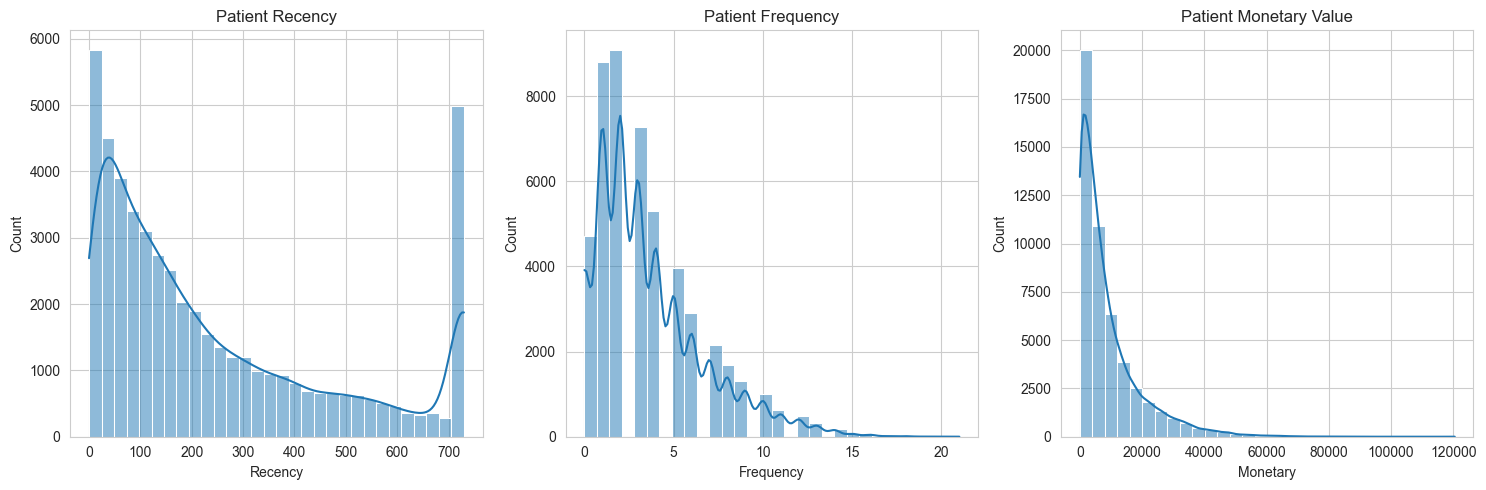

In [41]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(features["Recency"], bins=30, kde=True)
plt.title("Patient Recency")

plt.subplot(1, 3, 2)
sns.histplot(features["Frequency"], bins=30, kde=True)
plt.title("Patient Frequency")

plt.subplot(1, 3, 3)
sns.histplot(features["Monetary"], bins=30, kde=True)
plt.title("Patient Monetary Value")

plt.tight_layout()
plt.show()

In [42]:
output_path = "../outputs"

os.makedirs(output_path, exist_ok=True)

features.to_csv(
    f"{output_path}/patient_features.csv",
    index=False
)

print("Patient feature dataset saved successfully!")
print("Saved at: ../outputs/patient_features.csv")

Patient feature dataset saved successfully!
Saved at: ../outputs/patient_features.csv
